In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 16 + 17. Core implementation: Scale dot-product attention and numerical stability softmax

In [2]:
def softmax(x: np.ndarray, axis: int = -1):
  x = x - np.max(x, axis=axis, keepdims=True)  
  return np.exp(x) / np.sum(np.exp(x), axis=axis, keepdims=True)


In [3]:
def scaled_dot_product_attention(Q: np.ndarray, K: np.ndarray, V: np.ndarray):
  d_k = K.shape[-1]
  S = (Q @ K.T)/np.sqrt(d_k)
  A = softmax(S)
  C = A @ V
  return S, A, C

## Test experiment

In [4]:
import numpy as np

seq_len = 10
d_k = 64
d_v = 64

Q = np.random.randn(seq_len, d_k).astype(np.float32)
K = np.random.randn(seq_len, d_k).astype(np.float32)
V = np.random.randn(seq_len, d_v).astype(np.float32)

score, attention, context = scaled_dot_product_attention(Q, K, V)
print(f"Score 1: {score[0]}")
print(f"Attention 1: {attention[0]}")
print(f"Context 1: {context[0]}")

Score 1: [ 0.29858905 -0.6860044  -0.43140125 -0.1531163   0.44057521 -1.03453374
 -1.70367455 -0.43122298  0.07864667 -0.33582777]
Attention 1: [0.17070386 0.06377344 0.08226452 0.10866013 0.19674656 0.04500652
 0.02305002 0.08227919 0.13700095 0.0905148 ]
Context 1: [-0.01733605  0.5226629  -0.05151698 -0.72780718  0.21028801  0.11925174
  0.24175471 -0.48320957 -0.89420677 -0.12913837  0.21244897 -0.43714067
  0.09568694  0.74048456  0.02854745  0.35707268 -0.46745375 -0.19425545
 -0.12729423  0.01338259 -0.08791903  0.06264244 -0.53091549  0.02386692
  0.58920256  0.63030523  0.43669294  0.23256223  0.72534078  0.35900399
 -0.41132882 -0.42184503 -0.14553715  0.15990294  0.04095374  0.06715112
 -0.10327266 -0.23216483  0.28614868  0.59093706  0.43105848  0.09802078
  0.28734174 -0.11635575  0.6337872  -0.10538859 -0.1507496   0.95851516
 -0.18900141 -0.39241597 -0.52561954  0.24080204 -0.32645949  0.15851374
 -0.0614894   0.04732817  0.20523156  0.56982768  0.11592694  0.25581367
 

# Experiment 1 — Attention distribution

In [5]:
sentence = "The movie was surprisingly good despite a very slow beginning."
tokens = sentence.strip().split()
seq_len = len(tokens)
print(tokens)

['The', 'movie', 'was', 'surprisingly', 'good', 'despite', 'a', 'very', 'slow', 'beginning.']


In [6]:
rng = np.random.default_rng(42)
vector_size = 16
embedding_matrix = rng.standard_normal(size=(seq_len, vector_size))
print(embedding_matrix.shape)

(10, 16)


In [7]:
d_K = 16
W_K = rng.standard_normal(size=(d_K, d_K))
K = embedding_matrix @ W_K

Q = rng.standard_normal(size=(1, d_K))

In [8]:
scores = (Q @ K.T) / np.sqrt(d_K)
attention_weights = softmax(scores, axis=-1)
print("Scores shape:", scores.shape)
print("Weights shape:", attention_weights.shape)
print("Weights sum:", attention_weights.sum())

Scores shape: (1, 10)
Weights shape: (1, 10)
Weights sum: 1.0


In [9]:
results = pd.DataFrame({
    "Token": tokens,
    "Score": scores.flatten(),
    "Attention": attention_weights.flatten()
})

display(results)

,Token,Score,Attention
0,The,2.540950,0.037225
1,movie,4.158792,0.187698
2,was,-0.610697,0.001593
3,surprisingly,-7.351800,0.000002
4,good,0.522541,0.004946
5,despite,-1.575245,0.000607
6,a,-0.260621,0.002260
7,very,4.165400,0.188942
8,slow,4.976555,0.425215
9,beginning.,3.944623,0.151512


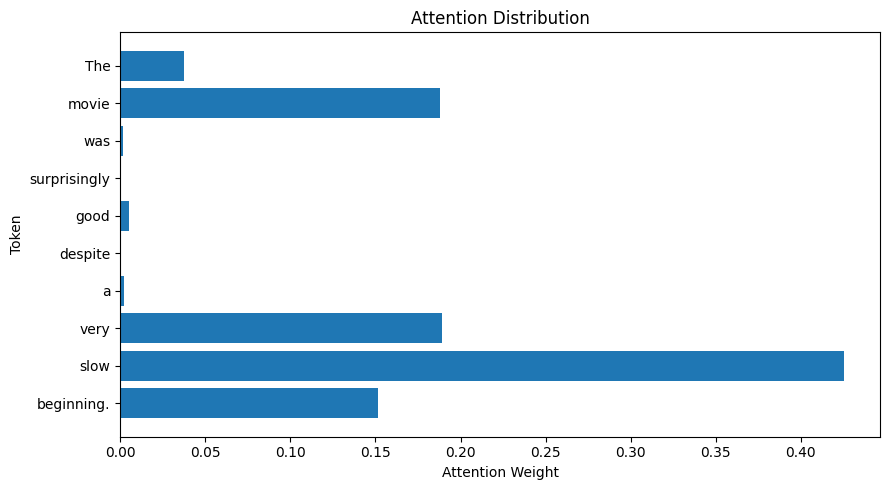

In [10]:
plt.figure(figsize=(9, 5))

plt.barh(
    tokens,
    attention_weights.flatten()
)

plt.xlabel("Attention Weight")
plt.ylabel("Token")
plt.title("Attention Distribution")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("Attention_Distribution_2.png", dpi=300, bbox_inches="tight")
plt.show()

# Experiment 2: Change Query vector

In [11]:
Q_2 = rng.standard_normal(size=(1, d_K))
scores2 = (Q_2 @ K.T) / np.sqrt(d_K)
attention_weights2 = softmax(scores2, axis=-1)
print("Scores Q2 shape:", scores2.shape)
print("Weights Q2 shape:", attention_weights2.shape)
print("Weights Q2 sum:", attention_weights2.sum())

Scores Q2 shape: (1, 10)
Weights Q2 shape: (1, 10)
Weights Q2 sum: 1.0000000000000002


In [12]:
results = pd.DataFrame({
    "Token": tokens,
    "Score2": scores2.flatten(),
    "Attention2": attention_weights2.flatten()
})

display(results)

,Token,Score2,Attention2
0,The,0.426322,0.049030
1,movie,2.850984,0.553964
2,was,0.633943,0.060344
3,surprisingly,1.195883,0.105847
4,good,0.443467,0.049878
5,despite,1.110184,0.097154
6,a,-1.201532,0.009627
7,very,0.739957,0.067093
8,slow,-1.607075,0.006418
9,beginning.,-3.905030,0.000645


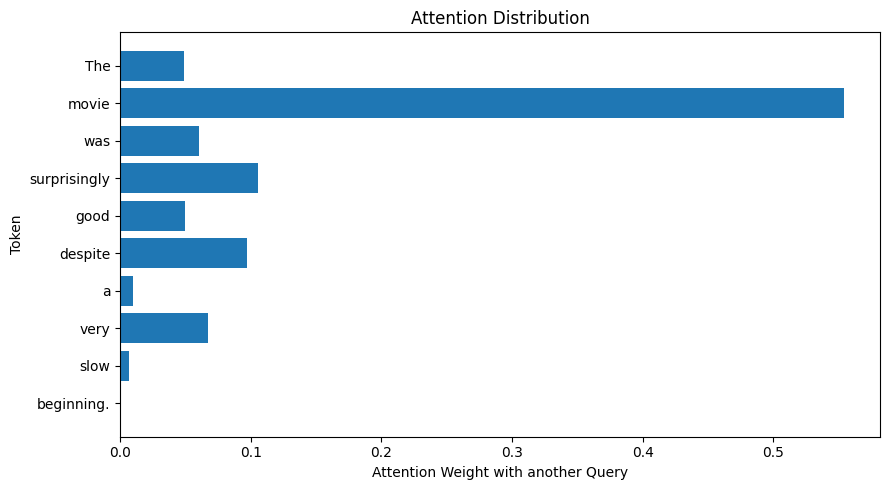

In [13]:
plt.figure(figsize=(9, 5))

plt.barh(
    tokens,
    attention_weights2.flatten()
)

plt.xlabel("Attention Weight with another Query")
plt.ylabel("Token")
plt.title("Attention Distribution")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("Attention_distribution_1.png", dpi=300, bbox_inches="tight")
plt.show()

# Experiment 3 — Attention visualization

In [14]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "google-bert/bert-base-uncased"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)

print("Device:", DEVICE)

/home/vitquay1708/miniconda3/envs/nlp/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [15]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, attn_implementation="eager")

model = model.to(DEVICE)
model.eval()

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1000.95it/s]
[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [16]:
def get_attention(sentence:str):
  inputs = tokenizer(sentence, return_tensors="pt").to(DEVICE)
  tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
  with torch.inference_mode():
    outputs = model(**inputs, output_attentions=True)

  attentions = torch.stack(outputs.attentions).squeeze(1).cpu().numpy()
  return tokens, attentions

In [17]:
sentence1 = "The cat that I adopted yesterday is sleeping."
sentence2 = "The book that I bought yesterday was expensive."
tokens1, attentions1 = get_attention(sentence1)
tokens2, attentions2 = get_attention(sentence2)

print("Tokens 1:", tokens1)
print("Attention shape 1:", attentions1.shape)

print("Tokens 2:", tokens2)
print("Attention shape 2:", attentions2.shape)

Tokens 1: ['[CLS]', 'the', 'cat', 'that', 'i', 'adopted', 'yesterday', 'is', 'sleeping', '.', '[SEP]']
Attention shape 1: (12, 12, 11, 11)
Tokens 2: ['[CLS]', 'the', 'book', 'that', 'i', 'bought', 'yesterday', 'was', 'expensive', '.', '[SEP]']
Attention shape 2: (12, 12, 11, 11)


In [18]:
def visualize_attention(tokens, attentions, layer=0, head=0, namefile=""):
    attention_matrix = attentions[layer, head]

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        attention_matrix,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    plt.xlabel("Key Tokens (Attended To)")
    plt.ylabel("Query Tokens")
    plt.title(f"BERT Attention — Layer {layer}, Head {head}")
    plt.tight_layout()
    plt.savefig(namefile, dpi=300, bbox_inches="tight")
    plt.show()

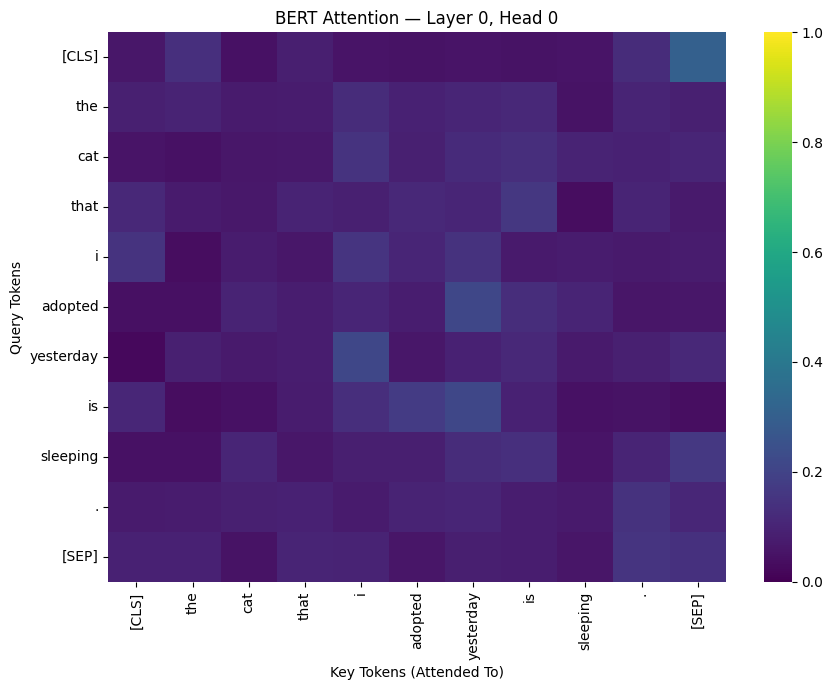

In [20]:
visualize_attention(
    tokens1,
    attentions1,
    layer=0,
    head=0,
    namefile="The_cat_that_I_adopted_yesterday_is_sleeping.png"
)

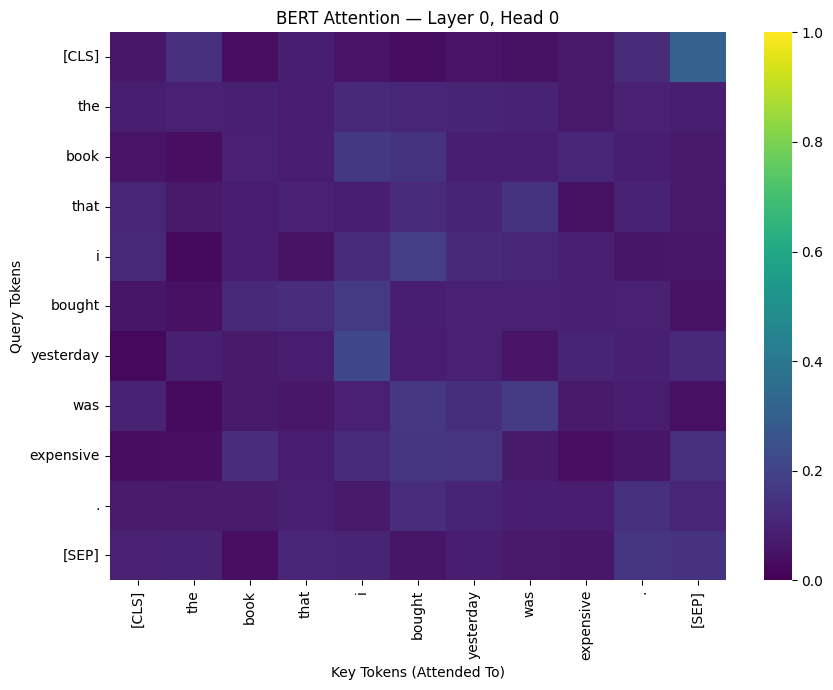

In [21]:
visualize_attention(
    tokens2,
    attentions2,
    layer=0,
    head=0,
    namefile="The_book_that_I_bought_yesterday_was_expensive.png"
)

In [22]:
def analyze_token(tokens, attentions, target_token,
                  layer=0, head=0):

    matrix = attentions[layer, head]

    token_idx = tokens.index(target_token)

    weights = matrix[token_idx]

    df = pd.DataFrame({
        "Key Token": tokens,
        "Attention Weight": weights
    })

    return df.sort_values(
        "Attention Weight",
        ascending=False
    )

In [23]:
for token in ["cat", "adopted", "sleeping"]:
    print(f"\nQuery token: {token}")

    df = analyze_token(
        tokens1,
        attentions1,
        target_token=token,
        layer=0,
        head=0
    )

    display(df)


Query token: cat


,Key Token,Attention Weight
4,i,0.144744
7,is,0.131080
6,yesterday,0.118888
10,[SEP],0.103104
8,sleeping,0.097081
9,.,0.090027
5,adopted,0.089179
3,that,0.064227
2,cat,0.061458
0,[CLS],0.053746



Query token: adopted


,Key Token,Attention Weight
6,yesterday,0.212031
7,is,0.125877
4,i,0.103351
8,sleeping,0.098437
2,cat,0.096061
5,adopted,0.081968
3,that,0.080235
10,[SEP],0.061069
9,.,0.057831
0,[CLS],0.042726



Query token: sleeping


,Key Token,Attention Weight
10,[SEP],0.160421
7,is,0.135738
6,yesterday,0.123593
2,cat,0.105415
9,.,0.097660
5,adopted,0.085815
4,i,0.085544
3,that,0.062235
8,sleeping,0.054081
0,[CLS],0.046492


In [24]:
def plot_token_attention(tokens, attentions, target_token,
                         layer=0, head=0, namefile=""):

    matrix = attentions[layer, head]

    idx = tokens.index(target_token)
    weights = matrix[idx]

    plt.figure(figsize=(9, 4))

    plt.bar(tokens, weights)

    plt.title(
        f"Attention from '{target_token}' "
        f"(Layer {layer}, Head {head})"
    )

    plt.xlabel("Key Tokens")
    plt.ylabel("Attention Weight")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(namefile, dpi=300, bbox_inches="tight")
    plt.show()

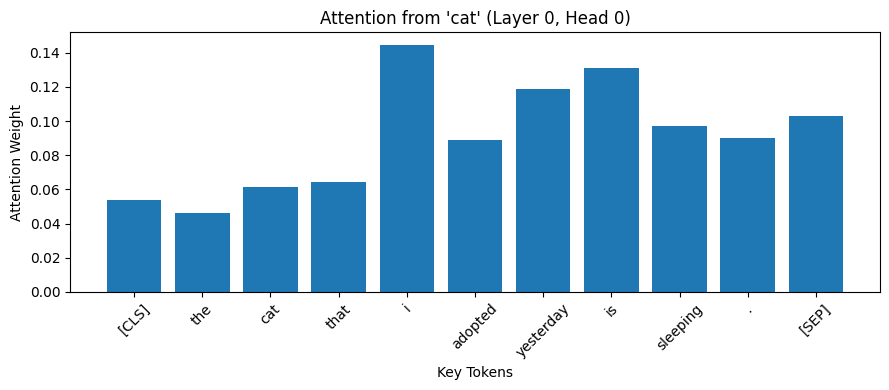

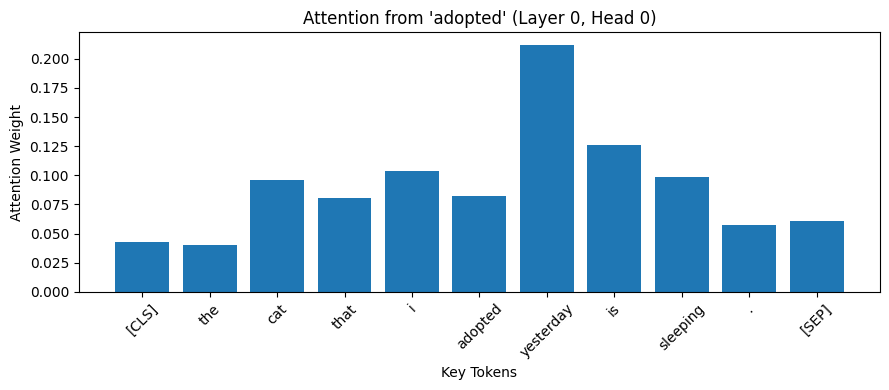

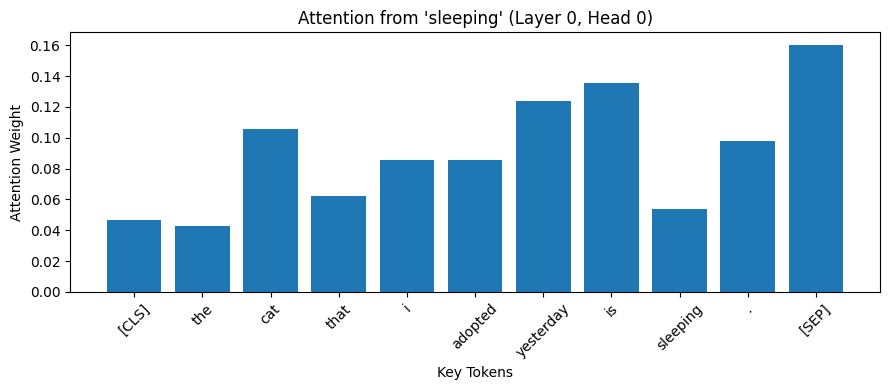

In [25]:
for token in ["cat", "adopted", "sleeping"]:
    plot_token_attention(
        tokens1,
        attentions1,
        token,
        layer=0,
        head=0,
        namefile=f"{token}.png"
    )

# Experiment 4 — RNN context vs Attention context

In [26]:
import torch
import torch.nn as nn

In [27]:
class LSTMClassifier(nn.Module):
  def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embedding_dim=embed_dim, padding_idx=0)
    self.lstm = nn.LSTM(input_size=embed_dim, hidden_size=hidden_dim, batch_first=True)
    self.classifier = nn.Linear(hidden_dim, num_classes)

  def forward(self, input_ids):
    lengths = (input_ids != 0).sum(dim=1).cpu()
    x = self.embedding(input_ids)
    packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
    _, (h_n, _) = self.lstm(packed)
    context = h_n[-1]
    return self.classifier(context)

In [28]:
class AttentionClassifier(nn.Module):
  def __init__(self, vocab_size, embed_dim, num_heads, num_classes):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embedding_dim=embed_dim, padding_idx=0)
    self.attention = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, batch_first=True)
    self.classifier = nn.Linear(embed_dim, num_classes)
  def forward(self, input_ids):
    mask = input_ids != 0
    x = self.embedding(input_ids)
    context, _ = self.attention(x, x, x, key_padding_mask=~mask, need_weights=False)
    mask_f = mask.unsqueeze(-1).to(context.dtype)
    pooled = (context * mask_f).sum(dim=1)/mask_f.sum(dim=1).clamp(min=1)
    return self.classifier(pooled)

In [29]:
DATA_PATH = "/home/vitquay1708/Study_Space/NLP/lab4/imdb/IMDB Dataset.csv"

df = pd.read_csv(DATA_PATH)

print(df.shape)
print(df.head())
print(df["sentiment"].value_counts())
print(df.isnull().sum())
df = df.dropna(subset=["review", "sentiment"]).copy()

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

assert df["label"].notna().all()
df["label"] = df["label"].astype(int)

(50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
review       0
sentiment    0
dtype: int64


In [30]:
import re
import html

def preprocess(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(preprocess)

In [31]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["label"]
)

print(len(train_df), len(val_df), len(test_df))

40000 5000 5000


In [32]:
from collections import Counter

MAX_VOCAB_SIZE = 20000
MAX_LENGTH = 100
BATCH_SIZE = 32

counter = Counter()

for text in train_df["clean_review"]:
    counter.update(text.split())

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, _ in counter.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

Vocabulary size: 20000


In [33]:
def encode_text(text, vocab, max_length):
    tokens = text.split()

    ids = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens[:max_length]
    ]

    # Padding
    ids += [vocab["<PAD>"]] * (max_length - len(ids))

    return ids

In [34]:
import torch
from torch.utils.data import TensorDataset, DataLoader

def create_dataloader(df, shuffle=False):
    X = [
        encode_text(text, vocab, MAX_LENGTH)
        for text in df["clean_review"]
    ]

    y = df["label"].astype(int).tolist()

    X = torch.tensor(X, dtype=torch.long)
    y = torch.tensor(y, dtype=torch.long)

    dataset = TensorDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

train_loader = create_dataloader(train_df, shuffle=True)
val_loader = create_dataloader(val_df)
test_loader = create_dataloader(test_df)

In [35]:
input_ids, labels = next(iter(train_loader))

print(input_ids.shape)  # torch.Size([32, 100])
print(labels.shape)     # torch.Size([32])

torch.Size([32, 100])
torch.Size([32])


## Model Initialization

In [36]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

vocab_size = len(vocab)

lstm_model = LSTMClassifier(
    vocab_size=vocab_size,
    embed_dim=64,
    hidden_dim=64,
    num_classes=2
).to(DEVICE)

attention_model = AttentionClassifier(
    vocab_size=vocab_size,
    embed_dim=64,
    num_heads=4,
    num_classes=2
).to(DEVICE)

In [37]:
input_ids, labels = next(iter(train_loader))

input_ids = input_ids.to(DEVICE)
labels = labels.to(DEVICE)

with torch.no_grad():
    lstm_logits = lstm_model(input_ids)
    attention_logits = attention_model(input_ids)

print("LSTM output:", lstm_logits.shape)
print("Attention output:", attention_logits.shape)

LSTM output: torch.Size([32, 2])
Attention output: torch.Size([32, 2])


In [38]:
import time
import torch.nn as nn

def train_model(model, train_loader, epochs=5, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for input_ids, labels in train_loader:
            input_ids = input_ids.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            logits = model(input_ids)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)

        avg_loss = total_loss / len(train_loader.dataset)

        print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f}")

    if DEVICE == "cuda":
        torch.cuda.synchronize()

    return time.perf_counter() - start_time

In [39]:
lstm_time = train_model(lstm_model, train_loader)

attention_time = train_model(attention_model, train_loader)

print(f"LSTM Training Time: {lstm_time:.2f}s")
print(f"Attention Training Time: {attention_time:.2f}s")

Epoch 1/5 - Loss: 0.6565
Epoch 2/5 - Loss: 0.6063
Epoch 3/5 - Loss: 0.4737
Epoch 4/5 - Loss: 0.3597
Epoch 5/5 - Loss: 0.3088
Epoch 1/5 - Loss: 0.4894
Epoch 2/5 - Loss: 0.3581
Epoch 3/5 - Loss: 0.2961
Epoch 4/5 - Loss: 0.2461
Epoch 5/5 - Loss: 0.2035
LSTM Training Time: 78.53s
Attention Training Time: 40.35s


In [40]:
from sklearn.metrics import accuracy_score, f1_score
def evaluate_model(model, test_loader):
    model.eval()

    all_preds = []
    all_labels = []

    device = next(model.parameters()).device

    with torch.inference_mode():
        for input_ids, labels in test_loader:
            input_ids = input_ids.to(device)
            logits = model(input_ids)
            predictions = torch.argmax(logits, dim=1)
            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="binary")

    return accuracy, f1

In [41]:
lstm_accuracy, lstm_f1 = evaluate_model(
    lstm_model,
    test_loader
)

attention_accuracy, attention_f1 = evaluate_model(
    attention_model,
    test_loader
)

In [42]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
lstm_params = count_parameters(lstm_model)
attention_params = count_parameters(attention_model)

In [43]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["LSTM", "Attention"],
    "Accuracy": [lstm_accuracy, attention_accuracy],
    "F1": [lstm_f1, attention_f1],
    "Training time (s)": [lstm_time, attention_time],
    "Parameters": [lstm_params, attention_params]
})

display(
    results.style.format({
        "Accuracy": "{:.4f}",
        "F1": "{:.4f}",
        "Training time (s)": "{:.2f}",
        "Parameters": "{:,}"
    })
)

,Model,Accuracy,F1,Training time (s),Parameters
0,LSTM,0.8334,0.8328,78.53,"1,313,410"
1,Attention,0.8362,0.8356,40.35,"1,296,770"


# Experiment 5 — Sequence length và computational cost

In [44]:
SEQUENCE_LENGTHS = [10, 100, 500, 1000, 10000]
D_K = 64
DTYPE = np.float32
rng = np.random.default_rng(42)
results = []

for T in SEQUENCE_LENGTHS:
    num_elements = T * T

    memory_bytes = num_elements * np.dtype(DTYPE).itemsize

    results.append({
        "Sequence Length": T,
        "Attention Matrix": f"{T} × {T}",
        "Elements": num_elements,
        "Memory (MiB)": memory_bytes / (1024 ** 2)
    })

df = pd.DataFrame(results)

display(df)

,Sequence Length,Attention Matrix,Elements,Memory (MiB)
0,10,10 × 10,100,0.000381
1,100,100 × 100,10000,0.038147
2,500,500 × 500,250000,0.953674
3,1000,1000 × 1000,1000000,3.814697
4,10000,10000 × 10000,100000000,381.469727


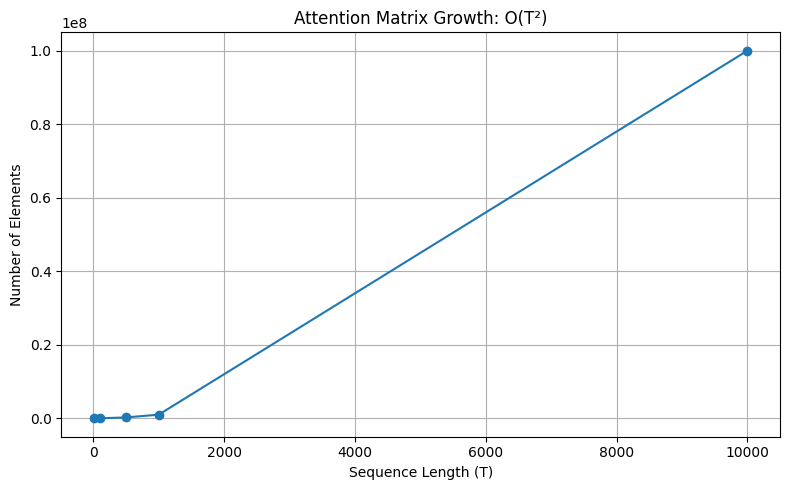

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    df["Sequence Length"],
    df["Elements"],
    marker="o"
)

plt.xlabel("Sequence Length (T)")
plt.ylabel("Number of Elements")
plt.title("Attention Matrix Growth: O(T²)")

plt.grid(True)
plt.tight_layout()
plt.savefig("Attention_Matrix_Growth.png",dpi=300, bbox_inches="tight")
plt.show()

In [46]:
def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


def compute_attention(Q, K):
    d_k = Q.shape[-1]

    scores = (Q @ K.T) * np.float32(1.0 / np.sqrt(d_k))
    weights = softmax(scores)

    return weights


benchmark_results = []

for T in SEQUENCE_LENGTHS:
    Q = rng.standard_normal((T, D_K)).astype(DTYPE)
    K = rng.standard_normal((T, D_K)).astype(DTYPE)

    # Warm-up
    compute_attention(Q, K)

    times = []

    for _ in range(5):
        start = time.perf_counter()

        weights = compute_attention(Q, K)

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    benchmark_results.append({
        "Sequence Length": T,
        "Avg Time (ms)": np.mean(times) * 1000,
        "Elements": weights.size
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df)

,Sequence Length,Avg Time (ms),Elements
0,10,0.088305,100
1,100,0.304735,10000
2,500,11.133753,250000
3,1000,23.209649,1000000
4,10000,2067.045166,100000000


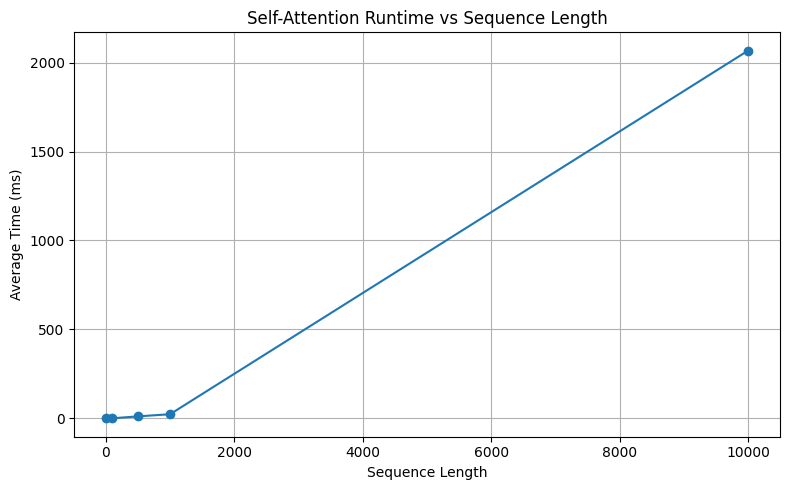

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    benchmark_df["Sequence Length"],
    benchmark_df["Avg Time (ms)"],
    marker="o"
)

plt.xlabel("Sequence Length")
plt.ylabel("Average Time (ms)")
plt.title("Self-Attention Runtime vs Sequence Length")

plt.grid(True)
plt.tight_layout()
plt.savefig("Self-Attention_Runtime_vs_Sequence_Length.png", dpi=300, bbox_inches="tight")
plt.show()

# Application - Context-aware sentiment

In [48]:
def extract_attention_and_predict(model, input_ids):
    model.eval()

    device = next(model.parameters()).device

    if isinstance(input_ids, list):
        input_ids = torch.tensor(input_ids, dtype=torch.long)

    if input_ids.ndim == 1:
        input_ids = input_ids.unsqueeze(0)

    input_ids = input_ids.to(device)

    with torch.inference_mode():
        mask = input_ids != 0

        x = model.embedding(input_ids)

        context, attention_weights = model.attention(
            x, x, x,
            key_padding_mask=~mask,
            need_weights=True,
            average_attn_weights=False
        )

        mask_f = mask.unsqueeze(-1).to(context.dtype)

        pooled = (
            (context * mask_f).sum(dim=1)
            / mask_f.sum(dim=1).clamp(min=1)
        )

        logits = model.classifier(pooled)
        probabilities = torch.softmax(logits, dim=-1)

    return {
        "logits": logits,
        "probabilities": probabilities,
        "attention_weights": attention_weights
    }

In [49]:
test_sentences = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent."
]

# Nhãn mong đợi do người đánh giá gán
expected_labels = [
    1,  # Positive
    0,  # Negative
    1   # Positive
]

In [50]:
import numpy as np

def predict_with_attention(model, sentence, max_length=64):
    # Match the normalization used for the training reviews.
    clean_sentence = preprocess(sentence)
    input_ids = encode_text(
        clean_sentence,
        vocab,
        max_length=max_length,
    )
    result = extract_attention_and_predict(
        model,
        input_ids
    )
    probabilities = result["probabilities"][0].cpu().numpy()
    predicted_label = int(np.argmax(probabilities))

    # Decode IDs with the same custom vocabulary used by the sentiment model.
    id_to_token = {idx: token for token, idx in vocab.items()}
    tokens = [id_to_token.get(token_id, "<UNK>") for token_id in input_ids]
    weights = (
        result["attention_weights"][0]
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    # Remove padded positions from both axes of the attention matrix.
    valid_length = next(
        (i for i, token_id in enumerate(input_ids)
         if token_id == vocab["<PAD>"]),
        len(input_ids)
    )
    tokens = tokens[:valid_length]
    weights = weights[:valid_length, :valid_length]

    return {
        "sentence": sentence,
        "prediction": "Positive" if predicted_label == 1 else "Negative",
        "predicted_label": predicted_label,
        "probability": float(probabilities[predicted_label]),
        "positive_probability": float(probabilities[1]),
        "negative_probability": float(probabilities[0]),
        "tokens": tokens,
        "attention": weights
    }


In [51]:
attention_model.eval()
results = []
for sentence, expected in zip(test_sentences, expected_labels):
    result = predict_with_attention(
        attention_model,
        sentence,
        max_length=100
    )
    result["expected_label"] = expected
    result["correct"] = result["predicted_label"] == expected

    results.append(result)

prediction_df = pd.DataFrame([
    {
        "Sentence": r["sentence"],
        "Prediction": r["prediction"],
        "Probability": r["probability"],
        "Expected": "Positive" if r["expected_label"] == 1 else "Negative",
        "Correct": r["correct"]
    }
    for r in results
])

display(
    prediction_df.style.format({
        "Probability": "{:.4f}"
    })
)

,Sentence,Prediction,Probability,Expected,Correct
0,I like this movie.,Negative,0.9891,Positive,False
1,I do not like this movie.,Negative,0.9991,Negative,True
2,"I thought this movie would be bad, but it was actually excellent.",Negative,0.6613,Positive,False


In [52]:
def visualize_attention(result, namefile=""):
    tokens = result["tokens"]
    weights = result["attention"]

    # Keep the matrix aligned with the non-padding token labels.
    valid_length = len(tokens)
    weights = weights[:valid_length, :valid_length]

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        weights,
        xticklabels=tokens,
        yticklabels=tokens,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    plt.xlabel("Key Tokens")
    plt.ylabel("Query Tokens")
    plt.title(
        f"{result['prediction']} "
        f"(p={result['probability']:.4f})"
    )

    plt.xticks(rotation=45)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.savefig(namefile, dpi=300, bbox_inches="tight")
    plt.show()


Sentence: I like this movie.
Prediction: Negative
Probability: 0.9890519976615906
Correct: False
Sentence: I do not like this movie.
Prediction: Negative
Probability: 0.999056875705719
Correct: True
Sentence: I thought this movie would be bad, but it was actually excellent.
Prediction: Negative
Probability: 0.6613246202468872
Correct: False


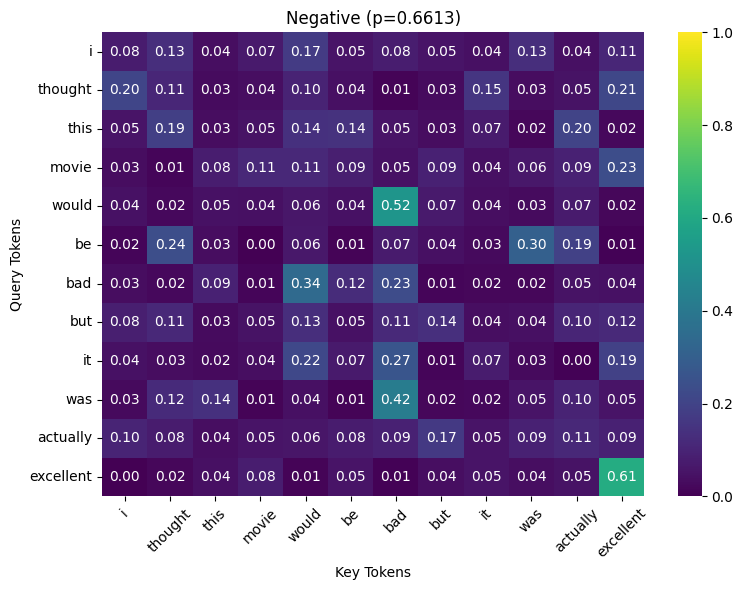

In [54]:
for result in results:
  print("Sentence:", result["sentence"])
  print("Prediction:", result["prediction"])
  print("Probability:", result["probability"])
  print("Correct:", result["correct"])

visualize_attention(result, namefile=f"{result['sentence']}.png")